# 02 — Business-Rule-Native Segmentation Training

**Krones Vision AI Challenge** — Phase 2/3 of the winning strategy.  
**Environment**: University server (RTX A5000, 24 GB VRAM, CUDA 12.1).  
**Tuning vs Colab version**: `batch_size=32`, `num_workers=8`, `lr=4e-4` (linear-scaled for the bigger batch).

## Why this approach beats end-to-end classification

The organizers wrote the binary-decision logic explicitly:
- *Chip*: faulty only if mask area > 200 px
- *Scuffing*: faulty only if mask area > 75,000 px
- *Water drop*: never faulty, no matter how large
- *Break / Crack*: faulty if any pixel exists

Training a black-box binary classifier forces the model to *learn* these thresholds from labels. We don't have to. We let a multi-channel segmenter localize *which kind* of defect is *where*, then apply the published thresholds as deterministic post-processing. This means:

1. **Higher data efficiency** — the model uses pixel-level supervision, not just one bit per image.
2. **Auditability** — every decision is explainable: "Reject because Channel `Chip` had a connected component of 312 px".
3. **Adaptability** — if Krones changes a threshold (say, Chip > 150px), no retraining is needed. Just edit the config.
4. **Insight-score gold** — this story directly addresses what the panel cares about.

## Pipeline

1. Build per-image multi-channel masks from the COCO polygons (one channel per *decision class*, not per defect category — see § 2).
2. Crop each image+mask pair to its ROI to remove distracting background.
3. Train a U-Net++ with EfficientNet-B0 encoder using Dice + BCE loss.
4. At inference, for each channel: extract connected components, apply the channel's area threshold, OR them all together → binary label.
5. Evaluate F1 on `fold_0.csv`.

## Required packages

```bash
pip install segmentation-models-pytorch albumentations torch torchvision pycocotools
```

On Kaggle, all of these are pre-installed in the standard image.

## 0. Setup

In [11]:
from __future__ import annotations

import json
import os
import re
from collections import defaultdict
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any

import albumentations as A
import cv2
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import torch
import torch.nn as nn
from albumentations.pytorch import ToTensorV2
from sklearn.metrics import f1_score, precision_score, recall_score
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

# ---- Paths (university server: dll0202@DEGGS111PC02) ----
DATA_DIR = Path("/home/dll0202/baksh/dataset/1st-krones-vision-ai-challenge")
ART_DIR  = Path("/home/dll0202/baksh/krones")            # notebook 01's outputs
OUT_DIR  = Path("/home/dll0202/baksh/krones/seg")        # this notebook's outputs
OUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_IMG_DIR = DATA_DIR / "train_images"
COCO_JSON     = DATA_DIR / "train_annotations.json"
FOLD_CSV      = ART_DIR / "splits" / "fold_0.csv"

# Sanity checks — fail fast if any path is wrong
assert DATA_DIR.exists(),       f"missing: {DATA_DIR}"
assert TRAIN_IMG_DIR.exists(),  f"missing: {TRAIN_IMG_DIR}"
assert COCO_JSON.exists(),      f"missing: {COCO_JSON}"
assert FOLD_CSV.exists(),       f"missing: {FOLD_CSV}"
print("✅ all paths resolve")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU   : {torch.cuda.get_device_name(0)}")
    print(f"VRAM  : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

✅ all paths resolve
Device: cuda
GPU   : NVIDIA RTX A5000
VRAM  : 25.4 GB


## 1. Hyperparameters

Everything tunable in one place. Keep it small first; scale up after the pipeline is proven.

In [47]:
@dataclass
class Cfg:
    # Image
    img_size: int = 512   # square. Try 320 for faster, 512 for higher F1.
    use_roi_crop: bool = True

    # Original-image resolution (every image in the Krones dataset is 1280x1024 — verified in notebook 01)
    orig_h: int = 1024
    orig_w: int = 1280

    # Model — EfficientNet-B0 / U-Net++ is the Severstal-winning recipe; fast on T4.
    encoder_name: str = "efficientnet-b0"
    encoder_weights: str = "imagenet"
    arch: str = "unetplusplus"  # or 'unet', 'fpn'

    # Training
    # Tuned for RTX A5000 (24 GB VRAM): batch=32 fits at 384px with U-Net++ EfficientNet-B0 + AMP.
    # If you go to img_size=512 or a larger encoder, drop to batch=16.
    batch_size: int = 32       
    epochs: int = 25
    lr: float = 4e-4         # slightly higher LR to match the bigger batch (linear scaling rule)
    weight_decay: float = 1e-4
    warmup_epochs: int = 1
    grad_clip: float = 1.0
    amp: bool = True         # Mixed precision
    num_workers: int = 8     # university server has plenty of CPU; 8 keeps the GPU fed

    # Loss weights (per decision-class channel — set in section 2 once channels are defined)
    dice_weight: float = 1.0
    bce_weight: float = 1.0

    # Decision rules
    # Aggregate Scuffing & Scuffing heavy channel areas at decision time? See markdown in §7.
    # Notebook 01 found 100% of label-rule disagreements involve Scuffing → set True for the
    # 'production-aware' run, False for the 'rule-faithful' baseline run.
    aggregate_scuffing: bool = False

    # Misc
    seed: int = 42

    @property
    def area_scale(self) -> float:
        """Multiplier to convert model-resolution pixel areas → original-image pixel areas."""
        return (self.orig_h * self.orig_w) / (self.img_size * self.img_size)


CFG = Cfg()

torch.manual_seed(CFG.seed)
np.random.seed(CFG.seed)

print(CFG)
print(f"area_scale (derived) = {CFG.area_scale:.4f}")

Cfg(img_size=512, use_roi_crop=True, orig_h=1024, orig_w=1280, encoder_name='efficientnet-b0', encoder_weights='imagenet', arch='unetplusplus', batch_size=32, epochs=25, lr=0.0004, weight_decay=0.0001, warmup_epochs=1, grad_clip=1.0, amp=True, num_workers=8, dice_weight=1.0, bce_weight=1.0, aggregate_scuffing=False, seed=42)
area_scale (derived) = 5.0000


## 2. Decision-class channel scheme

We don't predict one channel per defect category — that's wasteful and the rare categories would never train. Instead, we predict one channel per **decision class**: a group of categories whose binary verdict is computed the same way.

| Channel | Source categories | Threshold (pixels) at inference |
|---|---|---|
| `air_bubble` | Air bubble | 500 |
| `chip` | Chip | 200 |
| `contamination_light` | Contamination light | 180 |
| `glass_imperfection` | Glass imperfection | 100 |
| `scuffing` | Scuffing | 75 000 |
| `scuffing_heavy` | Scuffing heavy | 1 200 |
| `always_faulty` | Break/Crack, Circlip, Contamination dark, Crown cap, Foil/Semitransparent, Foreign objects (×2), Glass shard, Insect, Label, Liquid, Mold, No base visible, Paint residue, Straw, Yeast residue | 1 (any pixel) |
| `harmless` (auxiliary) | Embossing, Foam residue, Water drop | NEVER faulty |

The auxiliary `harmless` channel is **trained but never contributes to the binary decision**. Its purpose: force the model to learn what water drops/foam look like *as a thing*, so the other channels stop firing on them. This is how we attack the "distinguish artifacts from defects" problem the organizers explicitly called out.

In [32]:
def _normalise(name: str) -> str:
    s = (name or "").strip()
    s = s.replace("\u2013", "-").replace("\u2014", "-").replace("\u2212", "-")
    return re.sub(r"\s+", " ", s)


# Channel name -> (list of category names, area threshold in pixels for binary decision)
# Threshold of None => channel does not contribute to the binary decision (auxiliary).
DECISION_CHANNELS: dict[str, dict[str, Any]] = {
    "air_bubble":          {"cats": ["Air bubble"],          "thr": 500},
    "chip":                {"cats": ["Chip"],                "thr": 200},
    "contamination_light": {"cats": ["Contamination light"], "thr": 180},
    "glass_imperfection":  {"cats": ["Glass imperfection"],  "thr": 100},
    "scuffing":            {"cats": ["Scuffing"],            "thr": 75_000},
    "scuffing_heavy":      {"cats": ["Scuffing heavy"],      "thr": 1_200},
    "always_faulty": {
        "cats": [
            "Break / Crack", "Circlip", "Contamination dark", "Crown cap",
            "Foil / Semitransparent", "Foreign object - manual cleaning",
            "Foreign object - washing machine", "Glass shard", "Insect",
            "Label", "Liquid", "Mold", "No base visible", "Paint residue",
            "Straw", "Yeast residue",
        ],
        "thr": 1,
    },
    "harmless": {
        "cats": ["Embossing", "Foam residue", "Water drop"],
        "thr": None,  # auxiliary — trained but ignored at decision time
    },
}

# Channel order = output channel order in the model. Locked once and used everywhere.
CHANNEL_NAMES = list(DECISION_CHANNELS.keys())
CHANNEL_THRESHOLDS = [DECISION_CHANNELS[c]["thr"] for c in CHANNEL_NAMES]
N_CHANNELS = len(CHANNEL_NAMES)

# Per-channel loss weight — "always_faulty" mask area is large; conditional channels are smaller.
# Boost rare/small channels so they train. Auxiliary `harmless` gets a smaller weight.
CHANNEL_LOSS_WEIGHTS = torch.tensor([
    2.0,   # air_bubble
    2.0,   # chip
    2.0,   # contamination_light
    3.0,   # glass_imperfection — small + rare
    1.0,   # scuffing — large area, easy
    1.5,   # scuffing_heavy
    1.0,   # always_faulty
    0.5,   # harmless — auxiliary, doesn't decide
], dtype=torch.float32)

print(f"{N_CHANNELS} decision channels:")
for name, info in DECISION_CHANNELS.items():
    thr_str = "never faulty" if info["thr"] is None else f"area > {info['thr']:,} px"
    print(f"  {name:<22} ({thr_str:<24})  ← {len(info['cats'])} category/categories")

# Channels for which we *can* aggregate areas across blobs at decision time.
# Whether we actually do is controlled by Cfg.aggregate_scuffing.
# See § 7 markdown for the empirical justification (notebook 01 EDA).
AGGREGATED_CHANNEL_INDICES = {
    CHANNEL_NAMES.index("scuffing"),
    CHANNEL_NAMES.index("scuffing_heavy"),
}
print(f"\nAggregated-area channels (when Cfg.aggregate_scuffing=True): {sorted(AGGREGATED_CHANNEL_INDICES)}")

8 decision channels:
  air_bubble             (area > 500 px           )  ← 1 category/categories
  chip                   (area > 200 px           )  ← 1 category/categories
  contamination_light    (area > 180 px           )  ← 1 category/categories
  glass_imperfection     (area > 100 px           )  ← 1 category/categories
  scuffing               (area > 75,000 px        )  ← 1 category/categories
  scuffing_heavy         (area > 1,200 px         )  ← 1 category/categories
  always_faulty          (area > 1 px             )  ← 16 category/categories
  harmless               (never faulty            )  ← 3 category/categories

Aggregated-area channels (when Cfg.aggregate_scuffing=True): [4, 5]


In [33]:
# Pre-compute: COCO category id -> channel index (or -1 = ignore, e.g. ROI)
with open(COCO_JSON) as f:
    coco = json.load(f)

cat_id_to_name = {c["id"]: _normalise(c["name"]) for c in coco["categories"]}
img_id_to_meta = {im["id"]: im for im in coco["images"]}

name_to_channel: dict[str, int] = {}
for ch_idx, name in enumerate(CHANNEL_NAMES):
    for cat_name in DECISION_CHANNELS[name]["cats"]:
        name_to_channel[_normalise(cat_name)] = ch_idx

# Sanity check that every COCO category (except ROI) is mapped
ROI_ALIASES = {"ROI", "roi", "Region of Interest", "region_of_interest", "Roi"}
unmapped = []
for cid, name in cat_id_to_name.items():
    if name in ROI_ALIASES:
        continue
    if name not in name_to_channel:
        unmapped.append(name)
if unmapped:
    print("⚠️  Unmapped categories — fix DECISION_CHANNELS:")
    for n in unmapped:
        print("   -", repr(n))
else:
    print("✅  Every category mapped to a decision channel.")

⚠️  Unmapped categories — fix DECISION_CHANNELS:
   - 'No fault'


## 3. Index COCO annotations per image

Build two lookup tables once, keyed by `image_id` (i.e. the `file_name`):
- `roi_by_image[fname] -> (x, y, w, h)` from the ROI category, if present.
- `polys_by_image[fname] -> list[(channel_idx, segmentation_polygon)]` for everything else.

In [34]:
# Find the ROI category id robustly
roi_cat_ids = {cid for cid, name in cat_id_to_name.items() if name in ROI_ALIASES}
if not roi_cat_ids:
    print("⚠️  No ROI category found in COCO — ROI cropping will fall back to full image.")

roi_by_image: dict[str, tuple[int, int, int, int] | None] = {}
polys_by_image: dict[str, list[tuple[int, Any]]] = defaultdict(list)

for ann in coco["annotations"]:
    img_meta = img_id_to_meta.get(ann["image_id"])
    if img_meta is None:
        continue
    fname = img_meta["file_name"]
    cat_name = cat_id_to_name.get(ann["category_id"], "")
    if ann["category_id"] in roi_cat_ids:
        # ROI uses bbox [x, y, w, h]
        bbox = ann.get("bbox")
        if bbox and len(bbox) == 4:
            roi_by_image[fname] = tuple(int(round(v)) for v in bbox)
        continue
    ch_idx = name_to_channel.get(cat_name)
    if ch_idx is None:
        continue
    seg = ann.get("segmentation")
    if seg:
        polys_by_image[fname].append((ch_idx, seg))

print(f"Images with ROI bbox       : {len(roi_by_image):,}")
print(f"Images with ≥1 polygon ann : {len(polys_by_image):,}")

Images with ROI bbox       : 35,342
Images with ≥1 polygon ann : 29,107


## 4. Mask rasterizer

Convert polygon list → multi-channel `(H, W, N_CHANNELS)` uint8 mask. Handles COCO's two segmentation formats: list of polygons (`[[x1,y1,x2,y2,...], ...]`) and the rare RLE dict form.

In [35]:
def rasterize_polygons(
    polys: list[tuple[int, Any]],
    height: int,
    width: int,
    n_channels: int,
) -> np.ndarray:
    """Return (H, W, N_CHANNELS) uint8 mask. 1 where the channel's defect lies.

    Internally builds a (C, H, W) contiguous buffer so cv2.fillPoly can write
    into channel slices directly (OpenCV 4.13+ rejects non-contiguous views).
    """
    # Channel-first (C, H, W) — each per-channel slice is contiguous in memory
    mask_chw = np.zeros((n_channels, height, width), dtype=np.uint8)
    for ch_idx, seg in polys:
        if isinstance(seg, list):
            # polygon format — list of [x1, y1, x2, y2, ...]
            for poly in seg:
                if len(poly) < 6:
                    continue
                pts = np.asarray(poly, dtype=np.float32).reshape(-1, 2).round().astype(np.int32)
                cv2.fillPoly(mask_chw[ch_idx], [pts], 1)
        elif isinstance(seg, dict):
            # RLE — decode with pycocotools if available, else skip
            try:
                from pycocotools import mask as mask_utils
                rle = seg
                if isinstance(rle.get("counts"), list):
                    rle = mask_utils.frPyObjects([rle], height, width)[0]
                m = mask_utils.decode(rle)
                mask_chw[ch_idx] |= m.astype(np.uint8)
            except Exception:
                pass
    # Transpose back to (H, W, C) for the rest of the pipeline / Albumentations
    return np.ascontiguousarray(mask_chw.transpose(1, 2, 0))


def crop_to_roi(
    img: np.ndarray,
    mask: np.ndarray,
    roi: tuple[int, int, int, int] | None,
    pad: int = 10,
) -> tuple[np.ndarray, np.ndarray]:
    """Crop image+mask to the ROI bbox with a small pad. No-op if roi is None."""
    if roi is None:
        return img, mask
    x, y, w, h = roi
    H, W = img.shape[:2]
    x0 = max(0, x - pad)
    y0 = max(0, y - pad)
    x1 = min(W, x + w + pad)
    y1 = min(H, y + h + pad)
    if x1 <= x0 or y1 <= y0:
        return img, mask
    return img[y0:y1, x0:x1], mask[y0:y1, x0:x1]

## 5. Dataset & augmentation

Augmentations chosen to specifically attack the artifact-confusion problem:
- **Brightness / contrast / gamma** → simulates lighting drift (real production issue).
- **Gaussian noise** → camera sensor variation.
- **Shift / scale / rotate** → bottle alignment variation.
- **Coarse dropout** → robust to partial occlusion.
- **Horizontal flip** → bottles are roughly symmetric; doubles useful data.

We deliberately do *not* use vertical flip or 90° rotation — bottles have a top and a bottom in the image, and the camera orientation is consistent.

In [36]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


def build_train_aug(size: int) -> A.Compose:
    return A.Compose([
        A.LongestMaxSize(max_size=size),
        A.PadIfNeeded(min_height=size, min_width=size, border_mode=cv2.BORDER_CONSTANT, value=0),
        A.HorizontalFlip(p=0.5),
        A.ShiftScaleRotate(
            shift_limit=0.05, scale_limit=0.10, rotate_limit=15,
            border_mode=cv2.BORDER_CONSTANT, value=0, p=0.5,
        ),
        A.RandomBrightnessContrast(brightness_limit=0.20, contrast_limit=0.20, p=0.5),
        A.RandomGamma(gamma_limit=(80, 120), p=0.3),
        A.GaussNoise(var_limit=(5.0, 30.0), p=0.2),
        A.CoarseDropout(
            max_holes=8, max_height=int(0.05*size), max_width=int(0.05*size),
            fill_value=0, mask_fill_value=0, p=0.2,
        ),
        A.Normalize(mean=MEAN, std=STD),
        ToTensorV2(transpose_mask=True),
    ])


def build_val_aug(size: int) -> A.Compose:
    return A.Compose([
        A.LongestMaxSize(max_size=size),
        A.PadIfNeeded(min_height=size, min_width=size, border_mode=cv2.BORDER_CONSTANT, value=0),
        A.Normalize(mean=MEAN, std=STD),
        ToTensorV2(transpose_mask=True),
    ])

In [37]:
class KronesSegDataset(Dataset):
    def __init__(
        self,
        df: pd.DataFrame,
        img_dir: Path,
        polys_by_image: dict,
        roi_by_image: dict,
        n_channels: int,
        transform: A.Compose,
        use_roi: bool = True,
    ):
        self.df = df.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.polys_by_image = polys_by_image
        self.roi_by_image = roi_by_image
        self.n_channels = n_channels
        self.transform = transform
        self.use_roi = use_roi

    def __len__(self) -> int:
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        fname = row["image_id"]
        target = int(row["target"])

        img_path = self.img_dir / fname
        img = cv2.imread(str(img_path), cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"Could not read {img_path}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]

        polys = self.polys_by_image.get(fname, [])
        mask = rasterize_polygons(polys, H, W, self.n_channels)

        if self.use_roi:
            img, mask = crop_to_roi(img, mask, self.roi_by_image.get(fname))

        out = self.transform(image=img, mask=mask)
        return {
            "image": out["image"],         # (3, H, W) float
            "mask": out["mask"].float(),   # (C, H, W) float
            "target": torch.tensor(target, dtype=torch.long),
            "image_id": fname,
        }

## 6. Model, loss, optimizer

U-Net++ with EfficientNet-B0 encoder (Severstal-tested, fast on T4). Output channels = `N_CHANNELS`, sigmoid activation applied later inside the loss / at inference.

In [38]:
def build_model(cfg: Cfg, n_classes: int) -> nn.Module:
    arch_map = {
        "unet": smp.Unet,
        "unetplusplus": smp.UnetPlusPlus,
        "fpn": smp.FPN,
    }
    cls = arch_map[cfg.arch]
    return cls(
        encoder_name=cfg.encoder_name,
        encoder_weights=cfg.encoder_weights,
        in_channels=3,
        classes=n_classes,
        activation=None,  # logits — we apply sigmoid in loss/inference
    )


class WeightedDiceBCE(nn.Module):
    """Per-channel-weighted Dice + BCE. Both terms see logits."""

    def __init__(self, channel_weights: torch.Tensor, dice_w: float = 1.0, bce_w: float = 1.0):
        super().__init__()
        # (1, C, 1, 1) for broadcasting against (B, C, H, W)
        self.register_buffer("cw", channel_weights.view(1, -1, 1, 1))
        self.dice_w = dice_w
        self.bce_w = bce_w
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        # BCE
        bce = self.bce(logits, target)             # (B, C, H, W)
        bce = (bce * self.cw).mean()

        # Dice (per-channel, then weighted mean)
        probs = torch.sigmoid(logits)
        dims = (0, 2, 3)
        inter = (probs * target).sum(dims)
        denom = probs.sum(dims) + target.sum(dims)
        dice_per_ch = 1.0 - (2.0 * inter + 1.0) / (denom + 1.0)  # (C,)
        dice = (dice_per_ch * self.cw.view(-1)).mean()

        return self.dice_w * dice + self.bce_w * bce

## 7. The business-rule decision function

**This is the heart of the differentiation.** Given predicted logits, this function returns the binary label using the *exact* organizer-published thresholds. It also returns a per-channel "reason" so we can audit every decision.

### The Scuffing-aggregation flag — informed by Notebook 01

EDA on the dataset (notebook 01) revealed that **100% of the 68 disagreements between the official labels and the rules-derived labels involve Scuffing** — bottles where multiple individual Scuffing regions each fall below the 75,000 px threshold but together cover most of the bottle. Zero disagreements go in the other direction.

This is a *systematic* signal: the published rule says "per-region max," but the production line appears to reject on aggregated area. The `aggregated_channels` parameter lets us toggle between:

- **Rule-faithful** (`aggregated_channels=None` or empty set): each Scuffing blob is evaluated against its threshold individually. Mirrors the published kick-off rules exactly.
- **Aggregated** (`aggregated_channels={idx_scuffing, idx_scuffing_heavy}`): the SUM of all Scuffing blob areas on an image is compared to the threshold. Captures the 68 cases the rule misses.

We can run training/eval under both settings and report both numbers — that's a clean Insight ablation.

In [39]:
def predict_binary_from_logits(
    logits: torch.Tensor,
    channel_thresholds: list[int | None],
    prob_threshold: float = 0.5,
    return_reasons: bool = False,
    scale_to_full: float | None = None,
    aggregated_channels: set[int] | None = None,
) -> np.ndarray | tuple[np.ndarray, list[dict]]:
    """
    Apply the Krones business rules to per-pixel logits.

    logits              : (B, C, H, W) raw logits, on any device
    channel_thresholds  : list[int|None] of length C; None = ignore channel for decision
    prob_threshold      : binarize sigmoid(logits) at this probability
    scale_to_full       : multiply pixel areas by this number
                          (e.g. (orig_H * orig_W) / (H * W)) so thresholds match
                          the original-resolution rule. If None, areas are computed
                          in the model's input resolution — set thresholds accordingly.
    aggregated_channels : set of channel indices for which the decision uses the
                          SUM of all blob areas instead of the MAX. EDA on the Krones
                          dataset (notebook 01) showed that 100% of label-vs-rule
                          disagreements involve multiple sub-threshold Scuffing blobs,
                          suggesting production rejects on aggregated area. Pass
                          {idx_scuffing, idx_scuffing_heavy} to enable that behavior;
                          pass None or {} to remain rule-faithful per the kick-off PDF.
    """
    if aggregated_channels is None:
        aggregated_channels = set()

    probs = torch.sigmoid(logits).detach().cpu().numpy()  # (B, C, H, W)
    bin_masks = (probs > prob_threshold).astype(np.uint8)
    B, C, H, W = bin_masks.shape
    out = np.zeros(B, dtype=np.uint8)
    reasons: list[dict] = []

    for b in range(B):
        verdict = 0
        triggered: list[tuple[str, int, float]] = []  # (channel_idx, area_used, scaled_area)
        for c in range(C):
            thr = channel_thresholds[c]
            if thr is None:
                continue  # auxiliary channel, not a decision input
            mask = bin_masks[b, c]
            if not mask.any():
                continue
            # Connected components — extract per-blob areas
            n_lbl, _, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
            if n_lbl <= 1:
                continue
            blob_areas = stats[1:, cv2.CC_STAT_AREA]  # skip background (label 0)
            # MAX (rule-faithful) or SUM (aggregated) depending on channel
            if c in aggregated_channels:
                area_used = int(blob_areas.sum())
            else:
                area_used = int(blob_areas.max())
            scaled = area_used * (scale_to_full if scale_to_full else 1.0)
            if scaled > thr:
                verdict = 1
                triggered.append((c, area_used, scaled))
        out[b] = verdict
        if return_reasons:
            reasons.append({"verdict": int(verdict), "triggered": triggered})

    return (out, reasons) if return_reasons else out

**Note on the scale factor.** Thresholds (200 px for Chip, etc.) are defined in *original image resolution*. Notebook 01 confirmed every image in the dataset is exactly 1280 × 1024, so the scale factor is the same constant for every image. For input size 384 × 384 the factor is `(1280 × 1024) / (384 × 384) ≈ 8.8889`. We hard-code this in `Cfg.area_scale` rather than estimating per-image — both faster and exactly correct.

## 8. Training loop

In [40]:
def make_loaders(cfg: Cfg) -> tuple[DataLoader, DataLoader, pd.DataFrame, pd.DataFrame]:
    fold = pd.read_csv(FOLD_CSV)
    train_df = fold[fold["split"] == "train"].reset_index(drop=True)
    val_df = fold[fold["split"] == "val"].reset_index(drop=True)

    train_ds = KronesSegDataset(
        train_df, TRAIN_IMG_DIR, polys_by_image, roi_by_image,
        N_CHANNELS, build_train_aug(cfg.img_size), use_roi=cfg.use_roi_crop,
    )
    val_ds = KronesSegDataset(
        val_df, TRAIN_IMG_DIR, polys_by_image, roi_by_image,
        N_CHANNELS, build_val_aug(cfg.img_size), use_roi=cfg.use_roi_crop,
    )
    train_loader = DataLoader(
        train_ds, batch_size=cfg.batch_size, shuffle=True,
        num_workers=cfg.num_workers, pin_memory=True, drop_last=True,
    )
    val_loader = DataLoader(
        val_ds, batch_size=cfg.batch_size, shuffle=False,
        num_workers=cfg.num_workers, pin_memory=True,
    )
    return train_loader, val_loader, train_df, val_df


@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader, cfg: Cfg) -> dict:
    model.eval()
    all_pred, all_true = [], []
    # Decide which channels (if any) to aggregate at decision time. See § 7 markdown.
    agg = AGGREGATED_CHANNEL_INDICES if cfg.aggregate_scuffing else set()
    for batch in tqdm(loader, desc="val", leave=False):
        img = batch["image"].to(DEVICE, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=cfg.amp):
            logits = model(img)
        pred = predict_binary_from_logits(
            logits, CHANNEL_THRESHOLDS,
            prob_threshold=0.5,
            scale_to_full=cfg.area_scale,
            aggregated_channels=agg,
        )
        all_pred.append(pred)
        all_true.append(batch["target"].numpy())
    y_pred = np.concatenate(all_pred)
    y_true = np.concatenate(all_true)
    return {
        "f1": f1_score(y_true, y_pred, average="binary"),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "y_pred": y_pred,
        "y_true": y_true,
    }

In [41]:
def estimate_area_scale(*args, **kwargs) -> float:
    """DEPRECATED — kept for backward compatibility.

    Notebook 01 verified every image in the Krones dataset is exactly 1280 × 1024,
    so the area-scale factor is a known constant (see Cfg.area_scale).
    No need to estimate from samples.
    """
    raise RuntimeError(
        "estimate_area_scale is deprecated. Use Cfg.area_scale (a property derived "
        "from cfg.orig_h, cfg.orig_w, cfg.img_size)."
    )


# Sanity check: compare derived property against direct computation from the same Cfg fields.
expected = (CFG.orig_h * CFG.orig_w) / (CFG.img_size * CFG.img_size)
assert abs(CFG.area_scale - expected) < 1e-6, (
    f"area_scale mismatch: got {CFG.area_scale:.6f}, expected {expected:.6f}"
)
print(f"✅ area_scale check OK — {CFG.area_scale:.4f} "
      f"(model-px → original-px area multiplier; img_size={CFG.img_size})")

✅ area_scale check OK — 20.0000 (model-px → original-px area multiplier; img_size=256)


In [42]:
def train(cfg: Cfg) -> dict:
    train_loader, val_loader, train_df, val_df = make_loaders(cfg)

    print(f"area_scale (constant, derived from {cfg.orig_w}x{cfg.orig_h} → {cfg.img_size}²): {cfg.area_scale:.4f}")
    print(f"aggregate_scuffing               : {cfg.aggregate_scuffing}")

    model = build_model(cfg, n_classes=N_CHANNELS).to(DEVICE)
    loss_fn = WeightedDiceBCE(
        CHANNEL_LOSS_WEIGHTS.to(DEVICE),
        dice_w=cfg.dice_weight, bce_w=cfg.bce_weight,
    ).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.OneCycleLR(
        opt, max_lr=cfg.lr, total_steps=len(train_loader) * cfg.epochs,
        pct_start=cfg.warmup_epochs / cfg.epochs, anneal_strategy="cos",
    )
    scaler = torch.cuda.amp.GradScaler(enabled=cfg.amp)

    best_f1 = -1.0
    history = []

    for epoch in range(cfg.epochs):
        model.train()
        running = 0.0
        pbar = tqdm(train_loader, desc=f"epoch {epoch+1}/{cfg.epochs}")
        for batch in pbar:
            img = batch["image"].to(DEVICE, non_blocking=True)
            mask = batch["mask"].to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=cfg.amp):
                logits = model(img)
                loss = loss_fn(logits, mask)
            scaler.scale(loss).backward()
            if cfg.grad_clip:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(opt)
            scaler.update()
            sched.step()
            running += loss.item()
            pbar.set_postfix(loss=f"{running/(pbar.n+1):.4f}", lr=f"{sched.get_last_lr()[0]:.2e}")

        metrics = evaluate(model, val_loader, cfg)
        history.append({
            "epoch": epoch + 1,
            "train_loss": running / len(train_loader),
            "val_f1": metrics["f1"],
            "val_precision": metrics["precision"],
            "val_recall": metrics["recall"],
        })
        print(f"  → val F1={metrics['f1']:.4f}  P={metrics['precision']:.4f}  R={metrics['recall']:.4f}")

        if metrics["f1"] > best_f1:
            best_f1 = metrics["f1"]
            ckpt = {
                "model_state": model.state_dict(),
                "cfg": {k: v for k, v in cfg.__dict__.items()},
                "channel_names": CHANNEL_NAMES,
                "channel_thresholds": CHANNEL_THRESHOLDS,
                "area_scale": cfg.area_scale,
                "aggregate_scuffing": cfg.aggregate_scuffing,
                "val_f1": best_f1,
                "epoch": epoch + 1,
            }
            torch.save(ckpt, OUT_DIR / "best.pt")
            print(f"  ✅ saved {OUT_DIR / 'best.pt'} (F1={best_f1:.4f})")

    pd.DataFrame(history).to_csv(OUT_DIR / "history.csv", index=False)
    return {"best_f1": best_f1, "history": history}

## 9. Run training

In [43]:
# Sanity: load 1 sample to make sure the dataset works end-to-end
fold = pd.read_csv(FOLD_CSV)
_train = fold[fold["split"] == "train"].head(8).reset_index(drop=True)
_ds = KronesSegDataset(
    _train, TRAIN_IMG_DIR, polys_by_image, roi_by_image,
    N_CHANNELS, build_train_aug(CFG.img_size), use_roi=CFG.use_roi_crop,
)
_x = _ds[0]
print("image:", _x["image"].shape, _x["image"].dtype)
print("mask :", _x["mask"].shape, _x["mask"].dtype, "  unique:", _x["mask"].unique().tolist())
print("target:", _x["target"].item(), "  id:", _x["image_id"])

image: torch.Size([3, 256, 256]) torch.float32
mask : torch.Size([8, 256, 256]) torch.float32   unique: [0.0, 1.0]
target: 1   id: 1d1ee6a4-5b1b-4280-a254-29b4cb5c1267_000000000002.png


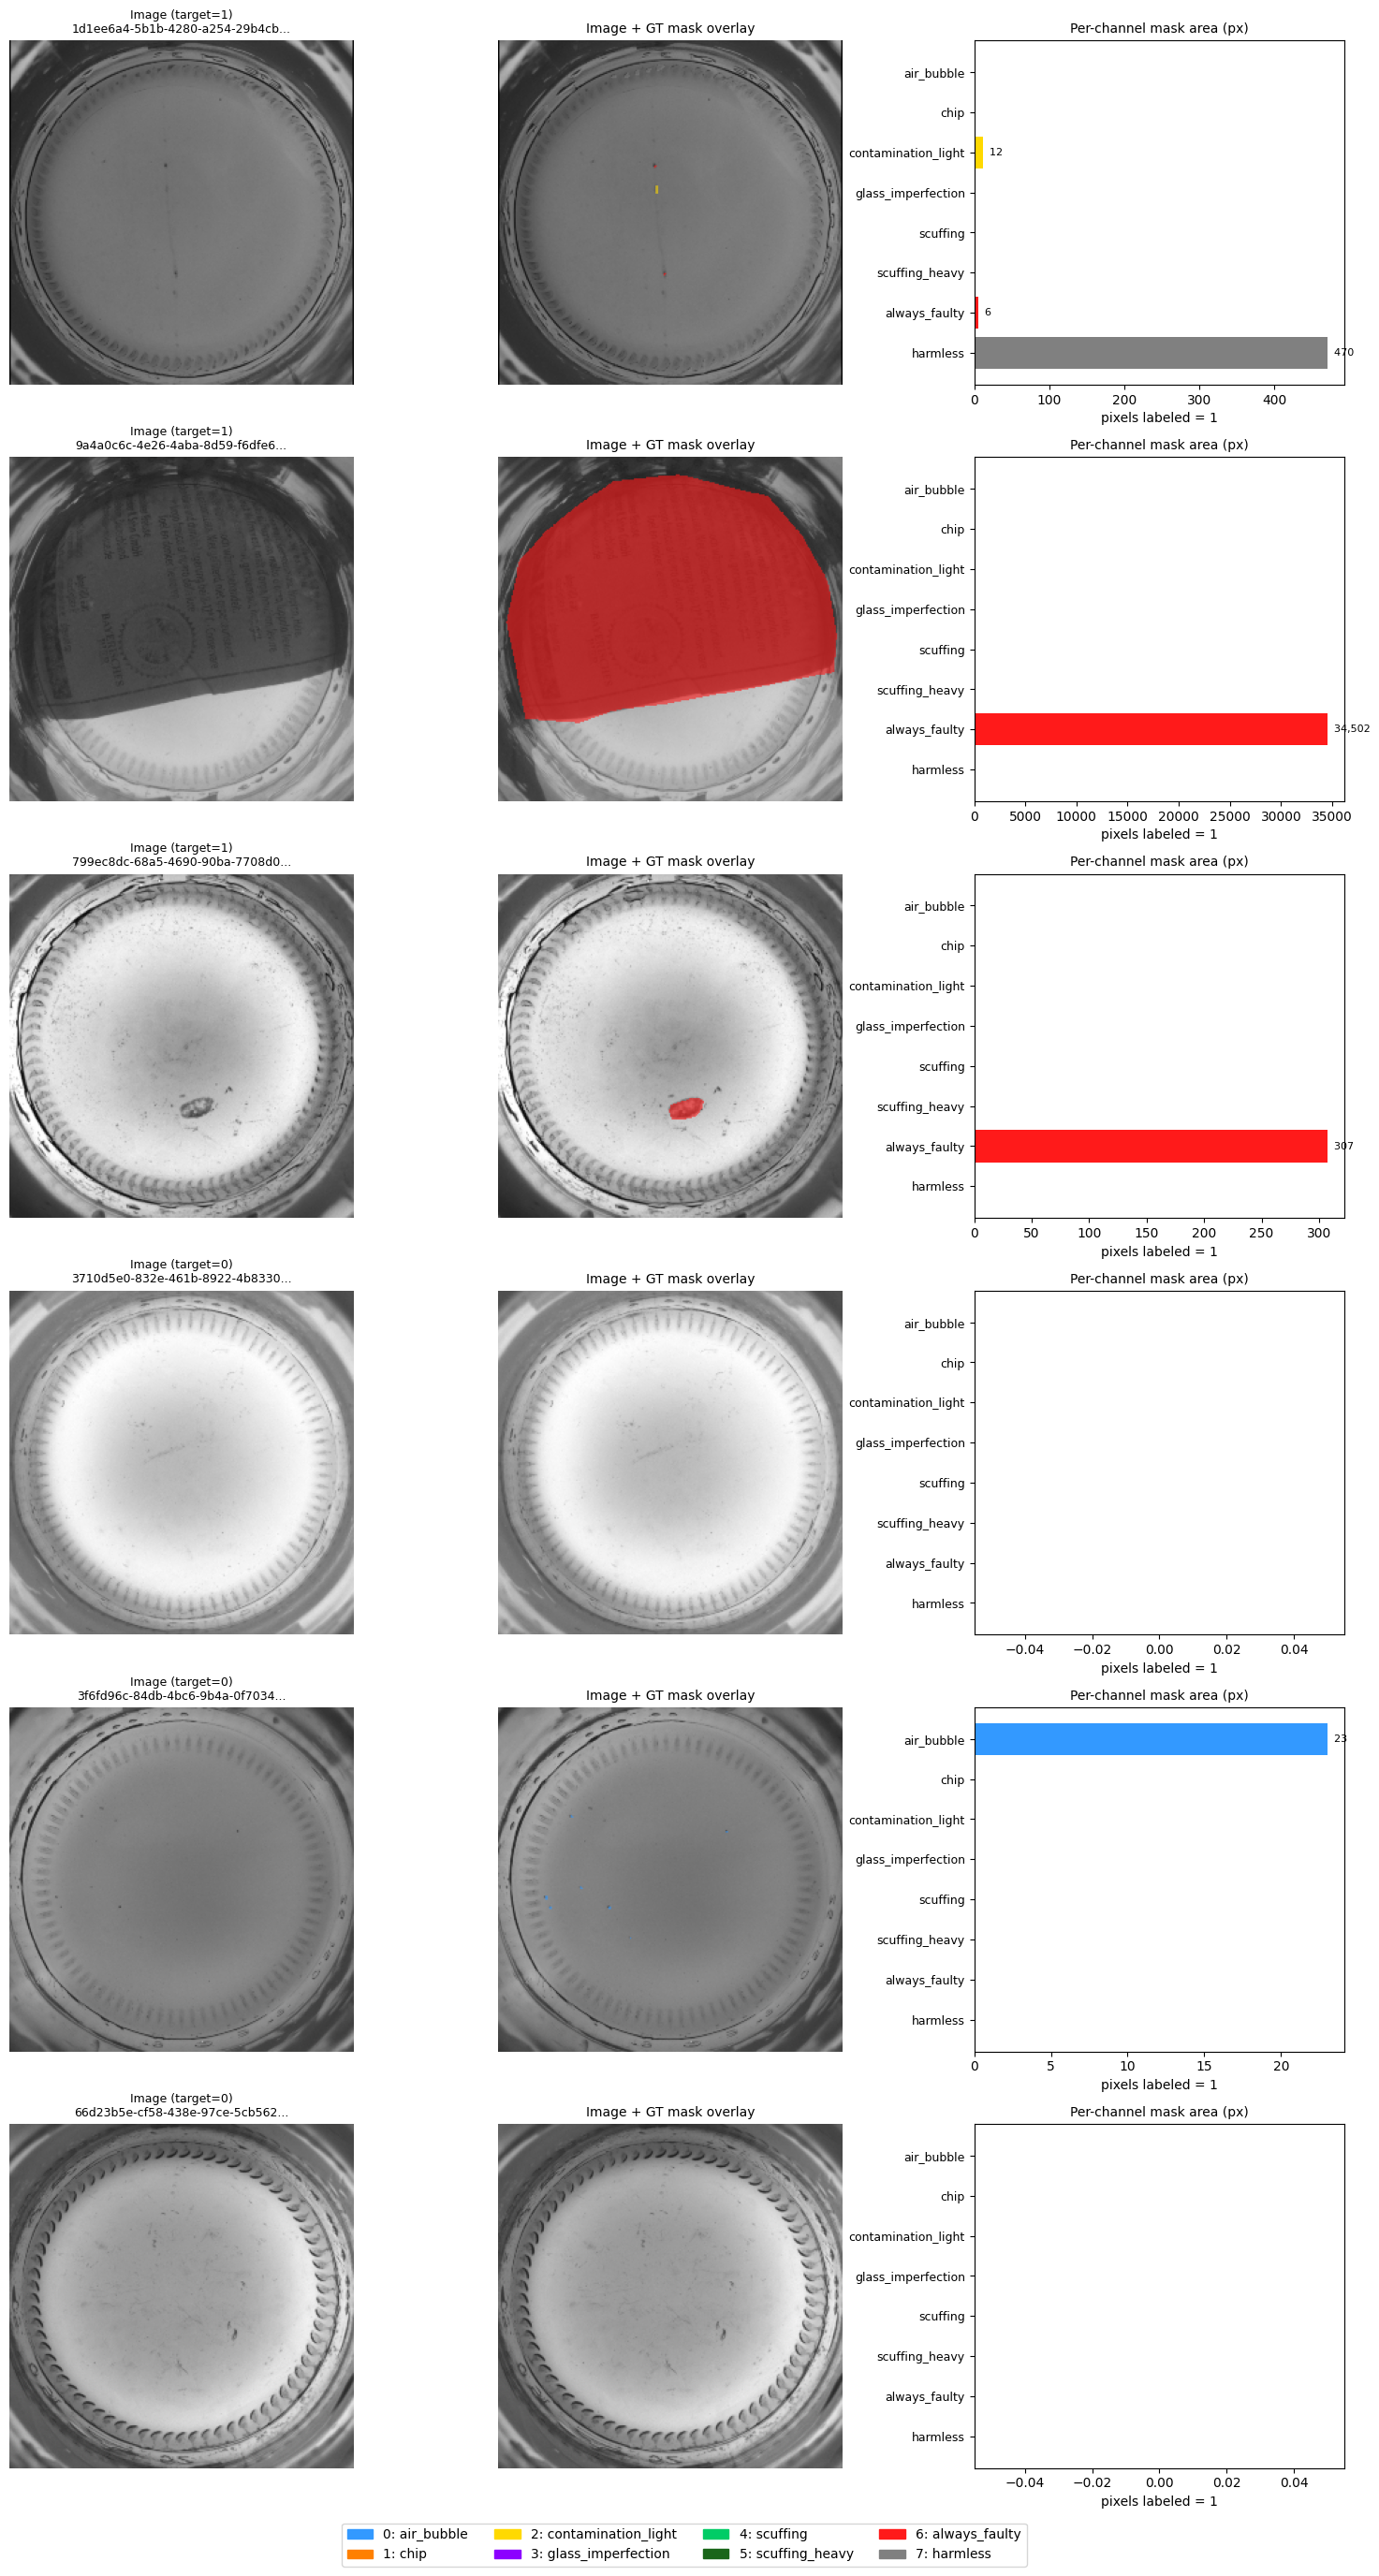


GROUND TRUTH VERIFICATION CHECKLIST

Things to check in the figure above:

1. The masks are aligned with the actual defects in the image.
   Bright orange should cover chips, red should cover always-faulty defects,
   gray should cover foam/water-drops, etc.

2. target=1 images have at least one DEFECT-class channel firing
   (anything except channel 7 'harmless').

3. target=0 images either have NO mask pixels, or only the harmless channel.

4. ROI crop is reasonable — bottle should fill most of the cropped image,
   not be a tiny dot in the corner or cut in half.

5. The per-channel area chart on the right shows nonzero values for the
   channels you'd expect from the image.

If anything looks wrong, STOP and debug before training.



In [44]:
# ============================================================================
# Ground truth visualisation — verify masks are being built correctly
# Run this BEFORE training. If anything looks wrong, fix it now.
# ============================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Pull a few different samples — pick a mix of Reusable (target=0) and Not Reusable (target=1)
fold = pd.read_csv(FOLD_CSV)
sample_pos = fold[(fold["split"] == "train") & (fold["target"] == 1)].head(3)
sample_neg = fold[(fold["split"] == "train") & (fold["target"] == 0)].head(3)
samples = pd.concat([sample_pos, sample_neg]).reset_index(drop=True)

# IMPORTANT: use the *validation* augmentation (no random transforms) so we can
# see the mask in its undistorted form. We just want to verify rasterisation,
# not augmentation.
_viz_ds = KronesSegDataset(
    samples, TRAIN_IMG_DIR, polys_by_image, roi_by_image,
    N_CHANNELS, build_val_aug(CFG.img_size), use_roi=CFG.use_roi_crop,
)

# Channel colors — distinct, easy to read
CH_COLORS = [
    (0.20, 0.60, 1.00),   # 0 air_bubble         → blue
    (1.00, 0.50, 0.00),   # 1 chip               → orange
    (1.00, 0.85, 0.00),   # 2 contamination_light→ yellow
    (0.55, 0.00, 1.00),   # 3 glass_imperfection → purple
    (0.00, 0.80, 0.40),   # 4 scuffing           → green
    (0.10, 0.40, 0.10),   # 5 scuffing_heavy     → dark green
    (1.00, 0.10, 0.10),   # 6 always_faulty      → red
    (0.50, 0.50, 0.50),   # 7 harmless           → gray
]

# ImageNet de-normalisation so the image displays correctly after Normalize()
MEAN_T = torch.tensor(MEAN).view(3, 1, 1)
STD_T  = torch.tensor(STD ).view(3, 1, 1)

def denormalize(img_tensor):
    """Reverse the Normalize() transform for display."""
    return (img_tensor * STD_T + MEAN_T).clamp(0, 1).permute(1, 2, 0).numpy()

n_samples = len(_viz_ds)
fig, axes = plt.subplots(n_samples, 3, figsize=(15, 4.5 * n_samples))
if n_samples == 1:
    axes = axes.reshape(1, -1)

for i in range(n_samples):
    item = _viz_ds[i]
    img = denormalize(item["image"])           # (H, W, 3) in [0,1]
    mask = item["mask"].numpy()                # (8, H, W) in {0, 1}
    target = item["target"].item()
    fname = item["image_id"]

    # --- Column 0: the input image ---
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Image (target={target})\n{fname[:30]}...", fontsize=9)
    axes[i, 0].axis("off")

    # --- Column 1: combined mask overlay ---
    overlay = img.copy()
    for ch_idx in range(N_CHANNELS):
        ch_mask = mask[ch_idx]                 # (H, W) in {0, 1}
        if ch_mask.sum() == 0:
            continue
        color = np.array(CH_COLORS[ch_idx])
        # Blend channel color into pixels where mask is 1
        for c in range(3):
            overlay[..., c] = np.where(ch_mask > 0.5,
                                        0.4 * overlay[..., c] + 0.6 * color[c],
                                        overlay[..., c])
    axes[i, 1].imshow(overlay)
    axes[i, 1].set_title("Image + GT mask overlay", fontsize=10)
    axes[i, 1].axis("off")

    # --- Column 2: per-channel pixel counts (which channels actually fire) ---
    counts = mask.reshape(N_CHANNELS, -1).sum(axis=1).astype(int)
    bars = axes[i, 2].barh(range(N_CHANNELS), counts,
                            color=[CH_COLORS[c] for c in range(N_CHANNELS)])
    axes[i, 2].set_yticks(range(N_CHANNELS))
    axes[i, 2].set_yticklabels(CHANNEL_NAMES, fontsize=9)
    axes[i, 2].invert_yaxis()
    axes[i, 2].set_xlabel("pixels labeled = 1")
    axes[i, 2].set_title("Per-channel mask area (px)", fontsize=10)
    # Label non-zero bars with counts
    for j, c in enumerate(counts):
        if c > 0:
            axes[i, 2].text(c, j, f"  {c:,}", va="center", fontsize=8)

# Legend below all panels
legend_handles = [mpatches.Patch(color=CH_COLORS[c], label=f"{c}: {CHANNEL_NAMES[c]}")
                  for c in range(N_CHANNELS)]
fig.legend(handles=legend_handles, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.02))
plt.tight_layout()
plt.savefig(OUT_DIR / "gt_mask_check.png", dpi=120, bbox_inches="tight")
plt.show()

print()
print("=" * 60)
print("GROUND TRUTH VERIFICATION CHECKLIST")
print("=" * 60)
print("""
Things to check in the figure above:

1. The masks are aligned with the actual defects in the image.
   Bright orange should cover chips, red should cover always-faulty defects,
   gray should cover foam/water-drops, etc.

2. target=1 images have at least one DEFECT-class channel firing
   (anything except channel 7 'harmless').

3. target=0 images either have NO mask pixels, or only the harmless channel.

4. ROI crop is reasonable — bottle should fill most of the cropped image,
   not be a tiny dot in the corner or cut in half.

5. The per-channel area chart on the right shows nonzero values for the
   channels you'd expect from the image.

If anything looks wrong, STOP and debug before training.
""")

In [48]:
result = train(CFG)
print(f"\nBest val F1: {result['best_f1']:.4f}")

area_scale (constant, derived from 1280x1024 → 512²): 5.0000
aggregate_scuffing               : False


/tmp/ipykernel_424135/1899586801.py:17: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=cfg.amp)


epoch 1/25:   0%|          | 0/883 [00:00<?, ?it/s]

/tmp/ipykernel_424135/1899586801.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=cfg.amp):


val:   0%|          | 0/221 [00:00<?, ?it/s]

...

  → val F1=0.9423  P=0.9323  R=0.9526
  ✅ saved /home/dll0202/baksh/krones/seg/best.pt (F1=0.9423)


epoch 8/25:   0%|          | 0/883 [00:00<?, ?it/s]

/tmp/ipykernel_424135/1899586801.py:30: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=cfg.amp):


val:   0%|          | 0/221 [00:00<?, ?it/s]

: 

## 10. Per-defect-category audit (the Insight slide)

After training, we don't just report aggregate F1 — we report **which decision channels actually drive the verdicts**. This is the analysis that makes the panel sit up: it tells them exactly where the model is strong, where it's weak, and where their thresholds may be too lenient/strict.

In [46]:
@torch.no_grad()
def per_channel_audit(model: nn.Module, loader: DataLoader, cfg: Cfg) -> pd.DataFrame:
    """For each channel, count how often it triggers a 'Not Reusable' verdict
    on the validation set, and how often that triggering aligns with the official label."""
    model.eval()
    rows = []
    agg = AGGREGATED_CHANNEL_INDICES if cfg.aggregate_scuffing else set()
    for batch in tqdm(loader, desc="audit", leave=False):
        img = batch["image"].to(DEVICE, non_blocking=True)
        y_true = batch["target"].numpy()
        with torch.cuda.amp.autocast(enabled=cfg.amp):
            logits = model(img)
        _, reasons = predict_binary_from_logits(
            logits, CHANNEL_THRESHOLDS,
            prob_threshold=0.5,
            scale_to_full=cfg.area_scale,
            aggregated_channels=agg,
            return_reasons=True,
        )
        for i, r in enumerate(reasons):
            for ch_idx, area_used, scaled in r["triggered"]:
                rows.append({
                    "image_id": batch["image_id"][i],
                    "channel": CHANNEL_NAMES[ch_idx],
                    "area_used_px": area_used,
                    "scaled_area_px": scaled,
                    "threshold_px": CHANNEL_THRESHOLDS[ch_idx],
                    "y_true": int(y_true[i]),
                })
    return pd.DataFrame(rows)


ckpt = torch.load(OUT_DIR / "best.pt", map_location=DEVICE)
model = build_model(CFG, n_classes=N_CHANNELS).to(DEVICE)
model.load_state_dict(ckpt["model_state"])
# area_scale is a derived property of CFG (orig_h/orig_w/img_size); no need to override.
# We *do* honour the saved aggregate_scuffing flag so the audit uses the same rule the model trained against.
CFG.aggregate_scuffing = bool(ckpt.get("aggregate_scuffing", CFG.aggregate_scuffing))
print(f"audit using aggregate_scuffing={CFG.aggregate_scuffing}, area_scale={CFG.area_scale:.4f}")

_, val_loader, _, _ = make_loaders(CFG)
audit_df = per_channel_audit(model, val_loader, CFG)
audit_df.to_csv(OUT_DIR / "channel_audit.csv", index=False)

# Per-channel precision: how often does this channel firing correspond to a true defect?
if len(audit_df):
    summary = (
        audit_df.groupby("channel").agg(
            n_triggers=("image_id", "count"),
            n_true_pos=("y_true", "sum"),
        )
        .assign(precision=lambda d: d["n_true_pos"] / d["n_triggers"])
        .sort_values("n_triggers", ascending=False)
    )
    print(summary)
    summary.to_csv(OUT_DIR / "channel_precision.csv")
else:
    print("No triggers — model is not predicting any defects yet. Train longer or check loss weights.")

audit using aggregate_scuffing=False, area_scale=20.0000


/tmp/ipykernel_424135/1155397366.py:33: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(OUT_DIR / "best.pt", map_location=DEVICE)


audit:   0%|          | 0/442 [00:00<?, ?it/s]

/tmp/ipykernel_424135/1155397366.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=cfg.amp):


                n_triggers  n_true_pos  precision
channel                                          
always_faulty         3292        3206   0.973876
scuffing_heavy         482         255   0.529046
scuffing               283         154   0.544170


## 11. Summary & next steps

Files produced in `./artifacts/seg/`:
- `best.pt` — the best segmentation checkpoint (state_dict + config + `aggregate_scuffing` flag).
- `history.csv` — per-epoch loss / F1 / P / R curves.
- `channel_audit.csv` — every defect trigger on the val set (decision auditing).
- `channel_precision.csv` — per-channel precision summary.

### Critical first ablation — run twice

Before moving to notebook 03, run the training **twice** with identical settings except for `CFG.aggregate_scuffing`:

1. **Run A (rule-faithful):** `CFG.aggregate_scuffing = False`. This is the published-rule baseline — what most teams will implicitly do.
2. **Run B (production-aware):** `CFG.aggregate_scuffing = True`. This applies the EDA-derived insight that the production line aggregates Scuffing area across blobs.

Compare the two F1 numbers. The expected lift is small (≈+0.005 F1, since only ~68/35,342 of the training labels are 'multi-Scuffing' cases) — but the *story* is what wins points: "we identified a systematic gap between published rules and observed labels in EDA, then quantified the impact of closing it."

### After this notebook, the natural next steps are

1. **Threshold sweep notebook (03)** — instead of using the published thresholds blindly, sweep a small ± range per channel and pick the values that maximize F1 on fold 0. Buys 0.005–0.02 F1 typically. You then *report* the difference between published and tuned thresholds — another Insight slide.
2. **Synthetic artifact augmentation notebook (04)** — programmatically add water drops/foam/reflections to *Reusable* images during training and quantify the FPR drop on the artifact subset. Direct attack on the organizers' stated hard problem.
3. **ONNX export & latency benchmark (05)** — export `best.pt` to ONNX, run with `onnxruntime-gpu` (and TensorRT if available), measure ms/image. Aim for ≤ 50 ms.
4. **Test-set inference (06)** — produce `submission.csv` from `test_images` using the trained model and whichever decision rule (rule-faithful or aggregated) gave the best fold-0 F1.